# Task 1: Egg Segmentation with Grounded-SAM

**Environment:** Kaggle notebook with a GPU and internet access enabled. Internet is needed to download the detector weights.

SAM finds regions by appearance, so filtering all of its masks by shape can also pick up hands, tables, and bowls. This notebook uses Grounded-SAM to focus the segmentation on eggs:

1. Grounding DINO finds boxes for the prompt *"an egg."*
2. SAM ViT-B uses each box to create a mask for the egg.
3. The masks are cleaned up and duplicate detections are removed.

The notebook saves the original and selected masks, combined masks, visual previews, and a CSV summary.

In [1]:
import os
import sys
import json
import random
import shutil
import subprocess
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import torch
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
else:
    print("WARNING: GPU is not enabled. In Kaggle: Settings → Accelerator → GPU.")

PyTorch: 2.11.0+cu128
Device: cuda
GPU: Tesla T4
GPU memory (GB): 14.56


In [2]:
# Install the Segment Anything package.
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q",
     "git+https://github.com/facebookresearch/segment-anything.git"],
    check=True
)

from segment_anything import sam_model_registry, SamAutomaticMaskGenerator
print("SAM package installed.")

SAM package installed.


In [3]:
# Download the pretrained SAM ViT-B weights.
CHECKPOINT_DIR = Path("/kaggle/working/checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = CHECKPOINT_DIR / "sam_vit_b_01ec64.pth"

if not CHECKPOINT_PATH.exists():
    subprocess.run(
        ["wget", "-q",
         "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth",
         "-O", str(CHECKPOINT_PATH)],
        check=True
    )

print("Checkpoint:", CHECKPOINT_PATH)
print("Size (GB):", round(CHECKPOINT_PATH.stat().st_size / 1024**3, 2))

Checkpoint: /kaggle/working/checkpoints/sam_vit_b_01ec64.pth
Size (GB): 0.35


In [4]:
# Load SAM ViT-B onto the selected device.
sam = sam_model_registry["vit_b"](checkpoint=str(CHECKPOINT_PATH))
sam.to(device=DEVICE)
sam.eval()

print("SAM ViT-B loaded on", DEVICE)

SAM ViT-B loaded on cuda


## Set up Grounding DINO and SAM

Grounding DINO finds boxes based on the text prompt. `SamPredictor` then uses each box to create a mask.

In [5]:
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection
from segment_anything import SamPredictor
from torchvision.ops import nms

DET_ID = "IDEA-Research/grounding-dino-base"
det_processor = AutoProcessor.from_pretrained(DET_ID)
det_model = AutoModelForZeroShotObjectDetection.from_pretrained(DET_ID).to(DEVICE).eval()

predictor = SamPredictor(sam)   # box-prompted SAM (replaces the automatic mask generator)
print("Detector + SAM predictor ready.")

preprocessor_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.74k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.24k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  933MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1182 [00:00<?, ?it/s]

Detector + SAM predictor ready.


In [6]:
# Check the folders mounted in Kaggle Input.
for p in sorted(Path("/kaggle/input").rglob("*")):
    if p.is_dir() and len(p.relative_to("/kaggle/input").parts) <= 5:
        print(p)

/kaggle/input/datasets
/kaggle/input/datasets/dewangchoudhary
/kaggle/input/datasets/dewangchoudhary/eggsss
/kaggle/input/datasets/dewangchoudhary/eggsss/Dataset
/kaggle/input/datasets/dewangchoudhary/eggsss/Dataset/test
/kaggle/input/datasets/dewangchoudhary/eggsss/Dataset/train
/kaggle/input/datasets/dewangchoudhary/eggsss/Dataset/valid


## Find and preview the dataset

Add the dataset through Kaggle's **Add Input** panel. The notebook searches subfolders for common image types. Check the paths it finds, especially if the dataset includes annotation images, and update `INPUT_DIR` or the filter if needed.

In [7]:
INPUT_DIR = Path("/kaggle/input/datasets/dewangchoudhary/eggsss/Dataset")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_paths = sorted(
    p for p in INPUT_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)

print("Images found:", len(image_paths))
for p in image_paths[:15]:
    print(p)

if not image_paths:
    raise RuntimeError("No images found. Attach the dataset using Kaggle's Add Input panel.")

Images found: 110
/kaggle/input/datasets/dewangchoudhary/eggsss/Dataset/test/egg/not_damaged_101_jpg.rf.479d12a2b41a5ec6d718dcdabd14b0c9.jpg
/kaggle/input/datasets/dewangchoudhary/eggsss/Dataset/test/egg/not_damaged_125_jpg.rf.b19353b1f84dcbef1ec088b850927bb3.jpg
/kaggle/input/datasets/dewangchoudhary/eggsss/Dataset/test/egg/not_damaged_14_jpg.rf.dc96559078b03433d2b65e5055904af1.jpg
/kaggle/input/datasets/dewangchoudhary/eggsss/Dataset/test/egg/not_damaged_152_jpg.rf.a57edb18d395ce87e23f7abccbd1ad69.jpg
/kaggle/input/datasets/dewangchoudhary/eggsss/Dataset/test/egg/not_damaged_153_jpg.rf.ea842e70f08e63e69bbcc74f1bc143a8.jpg
/kaggle/input/datasets/dewangchoudhary/eggsss/Dataset/test/egg/not_damaged_161_jpg.rf.fd216aa5e11e147fc1527478cceae94e.jpg
/kaggle/input/datasets/dewangchoudhary/eggsss/Dataset/test/egg/not_damaged_1_jpg.rf.d74c98a14f068b48c1f58fd573361f1f.jpg
/kaggle/input/datasets/dewangchoudhary/eggsss/Dataset/test/egg/not_damaged_30_jpg.rf.48e9261777355fe67139ac1c5eae596b.jpg
/k

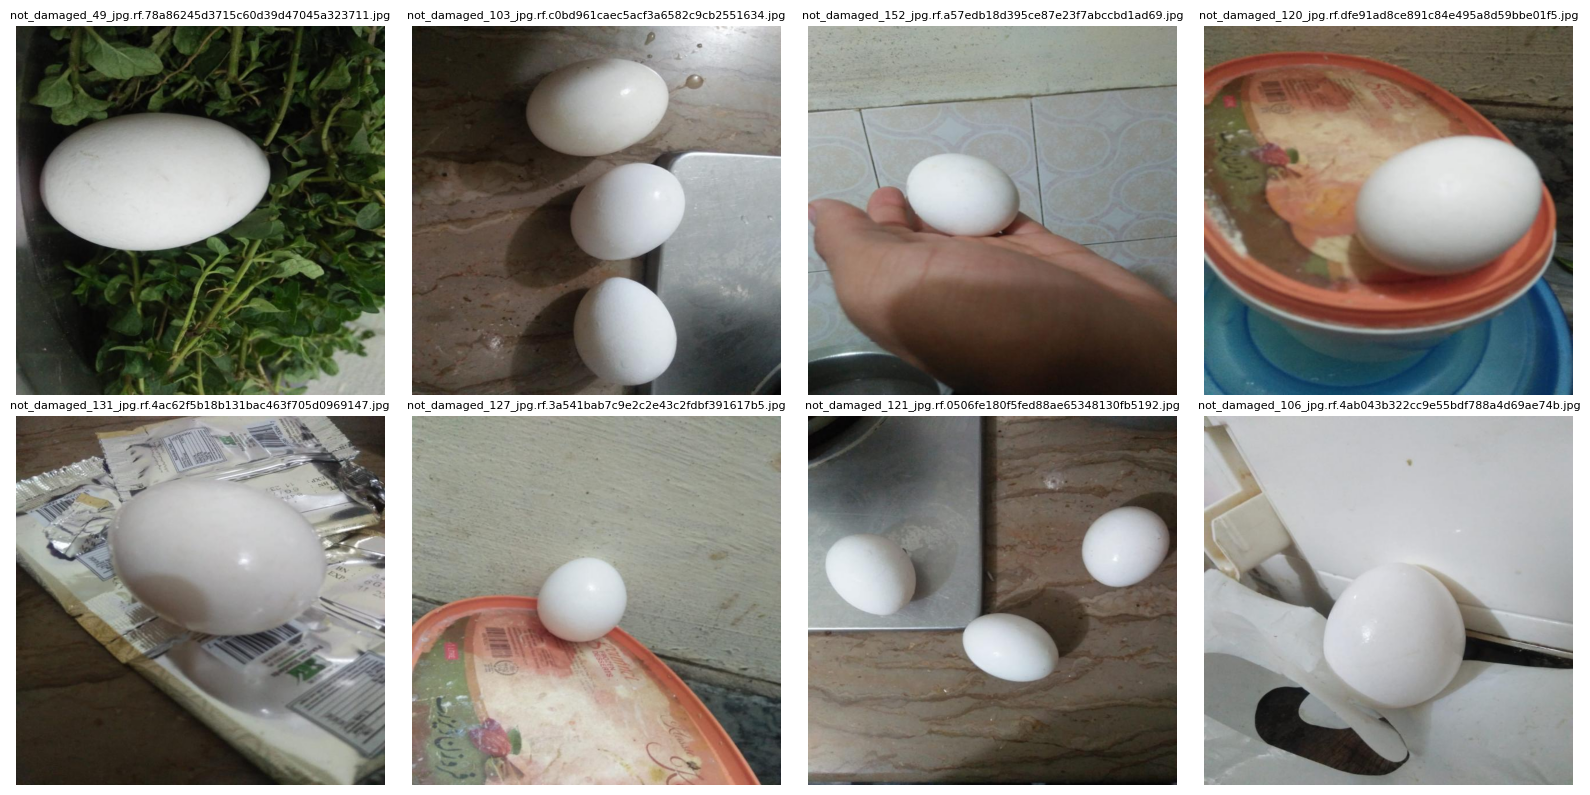

In [8]:
# Preview a few images before processing the dataset.
sample_paths = random.sample(image_paths, min(8, len(image_paths)))
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for ax, path in zip(axes, sample_paths):
    img = Image.open(path).convert("RGB")
    ax.imshow(img)
    ax.set_title(path.name, fontsize=8)
    ax.axis("off")

for ax in axes[len(sample_paths):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## Choose where to save the results

The results go in `/kaggle/working/task1_results`. After the notebook runs, you can download them from Kaggle's **Output** panel.

In [9]:
import shutil
OUTPUT_DIR = Path("/kaggle/working/task1_results")
shutil.rmtree(OUTPUT_DIR, ignore_errors=True)   # avoid stale files from earlier runs

RAW_MASK_DIR = OUTPUT_DIR / "raw_sam_candidates"
SELECTED_MASK_DIR = OUTPUT_DIR / "selected_masks"
COMBINED_MASK_DIR = OUTPUT_DIR / "combined_masks"
OVERLAY_DIR = OUTPUT_DIR / "overlays"
VIS_DIR = OUTPUT_DIR / "visualizations"

for folder in [RAW_MASK_DIR, SELECTED_MASK_DIR, COMBINED_MASK_DIR, OVERLAY_DIR, VIS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Output directory:", OUTPUT_DIR)

Output directory: /kaggle/working/task1_results


## Detect eggs and create their masks

Grounding DINO looks for regions matching *"an egg"*, and SAM creates a mask for each box. You can adjust `BOX_THRESH`, `MAX_BOX_AREA`, and `MIN_MASK_FILL` to change which detections are kept.

In [10]:
TEXT_PROMPT = "an egg."
BOX_THRESH, TEXT_THRESH = 0.35, 0.25
FALLBACK_THRESH = 0.15                       # used only if nothing passes BOX_THRESH
MIN_BOX_AREA, MAX_BOX_AREA = 0.003, 0.85     # fraction of image area
BOX_NMS_IOU = 0.5
MIN_MASK_FILL = 0.45                         # mask area / box area (an ellipse fills ~0.78)
DUPLICATE_MASK_IOU = 0.75


def detect_boxes(image_pil, thr):
    inputs = det_processor(images=image_pil, text=TEXT_PROMPT, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        outputs = det_model(**inputs)
    kw = dict(text_threshold=TEXT_THRESH, target_sizes=[image_pil.size[::-1]])
    try:   # argument name differs across transformers versions
        res = det_processor.post_process_grounded_object_detection(
            outputs, inputs.input_ids, threshold=thr, **kw)[0]
    except TypeError:
        res = det_processor.post_process_grounded_object_detection(
            outputs, inputs.input_ids, box_threshold=thr, **kw)[0]
    return res["boxes"].cpu(), res["scores"].cpu()


def get_egg_boxes(image_pil):
    W, H = image_pil.size
    boxes, scores = detect_boxes(image_pil, BOX_THRESH)
    used_fallback = False
    if len(boxes) == 0:
        boxes, scores = detect_boxes(image_pil, FALLBACK_THRESH)
        used_fallback = True

    if len(boxes):
        area = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1]) / (W * H)
        keep = (area >= MIN_BOX_AREA) & (area <= MAX_BOX_AREA)
        boxes, scores = boxes[keep], scores[keep]
    if len(boxes):
        keep = nms(boxes, scores, BOX_NMS_IOU)
        boxes, scores = boxes[keep], scores[keep]
    if used_fallback and len(boxes):         # low-confidence: keep only the best box
        boxes, scores = boxes[:1], scores[:1]
    return boxes.numpy(), scores.numpy()


def clean_mask(mask):
    """Keep the largest connected component and fill holes."""
    m = mask.astype(np.uint8)
    contours, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return None
    out = np.zeros_like(m)
    cv2.drawContours(out, [max(contours, key=cv2.contourArea)], -1, 1, thickness=-1)
    return out.astype(bool)

In [11]:
def binary_mask_iou(mask1, mask2):
    intersection = np.logical_and(mask1, mask2).sum()
    union = np.logical_or(mask1, mask2).sum()
    return float(intersection / (union + 1e-6))


def remove_duplicate_masks(candidates, iou_threshold=DUPLICATE_MASK_IOU):
    kept = []
    for c in sorted(candidates, key=lambda c: c["score"], reverse=True):
        if not any(binary_mask_iou(c["mask"], k["mask"]) > iou_threshold for k in kept):
            kept.append(c)
    return kept


def segment_eggs(image):
    """Returns (image_rgb, raw_masks, selected) - same interface the processing loop expects."""
    image_rgb = np.asarray(image.convert("RGB"))
    boxes, det_scores = get_egg_boxes(image)

    raw_masks, candidates = [], []
    if len(boxes):
        predictor.set_image(image_rgb)
        for box, det_score in zip(boxes, det_scores):
            masks, ious, _ = predictor.predict(box=box[None, :], multimask_output=False)
            raw_masks.append({"segmentation": masks[0]})
            m = clean_mask(masks[0])
            if m is None:
                continue
            box_area = (box[2] - box[0]) * (box[3] - box[1])
            fill = m.sum() / (box_area + 1e-6)
            if fill < MIN_MASK_FILL:
                continue
            candidates.append({
                "mask": m,
                "score": float(det_score),
                "features": {"fill": float(fill)},
                "predicted_iou": float(ious[0]),
                "stability_score": 0.0,
            })
    return image_rgb, raw_masks, remove_duplicate_masks(candidates)

## Run segmentation across the dataset

The loop keeps each image's subfolder path so files with the same name won't overwrite one another. It saves the original masks as compressed NumPy files and the selected and combined masks as PNGs.

In [12]:
records = []
failures = []

for image_path in tqdm(image_paths, desc="SAM segmentation"):
    relative_path = image_path.relative_to(INPUT_DIR)
    stem = image_path.stem
    subdir = relative_path.parent

    raw_dir = RAW_MASK_DIR / subdir
    selected_dir = SELECTED_MASK_DIR / subdir
    combined_dir = COMBINED_MASK_DIR / subdir
    overlay_dir = OVERLAY_DIR / subdir
    vis_dir = VIS_DIR / subdir

    for folder in [raw_dir, selected_dir, combined_dir, overlay_dir, vis_dir]:
        folder.mkdir(parents=True, exist_ok=True)

    try:
        image = Image.open(image_path).convert("RGB")
        image_rgb, raw_masks, selected = segment_eggs(image)

        # Keep all raw SAM masks so they can be filtered again later.
        if raw_masks:
            raw_stack = np.stack([
                item["segmentation"].astype(np.uint8) for item in raw_masks
            ])
            np.savez_compressed(raw_dir / f"{stem}_raw.npz", masks=raw_stack)
        else:
            np.savez_compressed(
                raw_dir / f"{stem}_raw.npz",
                masks=np.empty((0, image_rgb.shape[0], image_rgb.shape[1]), dtype=np.uint8)
            )

        # Save each selected mask as its own image.
        for i, candidate in enumerate(selected, start=1):
            mask_u8 = candidate["mask"].astype(np.uint8) * 255
            cv2.imwrite(str(selected_dir / f"{stem}_candidate_{i:02d}.png"), mask_u8)

        # Combine the selected masks into one binary image.
        combined = np.zeros(image_rgb.shape[:2], dtype=np.uint8)
        for candidate in selected:
            combined[candidate["mask"]] = 255

        cv2.imwrite(str(combined_dir / f"{stem}_mask.png"), combined)

        # Create a colored overlay to make the masks easier to inspect.
        overlay = image_rgb.copy()
        rng = np.random.default_rng(SEED)
        for candidate in selected:
            color = rng.integers(60, 256, size=3, dtype=np.uint8)
            mask = candidate["mask"]
            overlay[mask] = (
                0.5 * overlay[mask].astype(np.float32) +
                0.5 * color.astype(np.float32)
            ).astype(np.uint8)

            contours, _ = cv2.findContours(
                mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
            )
            cv2.drawContours(overlay, contours, -1, (255, 0, 0), 2)

        cv2.imwrite(
            str(overlay_dir / f"{stem}_overlay.png"),
            cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR)
        )

        # Save a side-by-side view for a quick visual check.
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        axes[0].imshow(image_rgb)
        axes[0].set_title("Original")
        axes[1].imshow(combined, cmap="gray", vmin=0, vmax=255)
        axes[1].set_title("Selected mask union")
        axes[2].imshow(overlay)
        axes[2].set_title(f"Candidates: {len(selected)}")
        for ax in axes:
            ax.axis("off")
        fig.tight_layout()
        fig.savefig(vis_dir / f"{stem}_visualization.png", dpi=120, bbox_inches="tight")
        plt.close(fig)

        records.append({
            "image": str(relative_path),
            "width": int(image_rgb.shape[1]),
            "height": int(image_rgb.shape[0]),
            "raw_sam_masks": len(raw_masks),
            "selected_candidates": len(selected),
            "selected_mask_pixels": int(np.count_nonzero(combined)),
            "status": "success",
            "error": ""
        })

    except Exception as exc:
        failures.append({"image": str(relative_path), "error": repr(exc)})
        records.append({
            "image": str(relative_path),
            "width": None,
            "height": None,
            "raw_sam_masks": None,
            "selected_candidates": None,
            "selected_mask_pixels": None,
            "status": "failed",
            "error": repr(exc)
        })

    if DEVICE == "cuda":
        torch.cuda.empty_cache()

results_df = pd.DataFrame(records)
results_df.to_csv(OUTPUT_DIR / "segmentation_results.csv", index=False)
pd.DataFrame(failures, columns=["image", "error"]).to_csv(
    OUTPUT_DIR / "failed_images.csv", index=False
)

print("Finished.")
print("Successful:", int((results_df["status"] == "success").sum()))
print("Failed:", int((results_df["status"] == "failed").sum()))

SAM segmentation:   0%|          | 0/110 [00:00<?, ?it/s]

Finished.
Successful: 110
Failed: 0


## Review a sample of the results

Check that the masks cover the eggs, avoid other objects, and keep touching eggs separate. If eggs are missed, try lowering `BOX_THRESH`. If extra regions are selected, try raising it or lowering `MAX_BOX_AREA`.

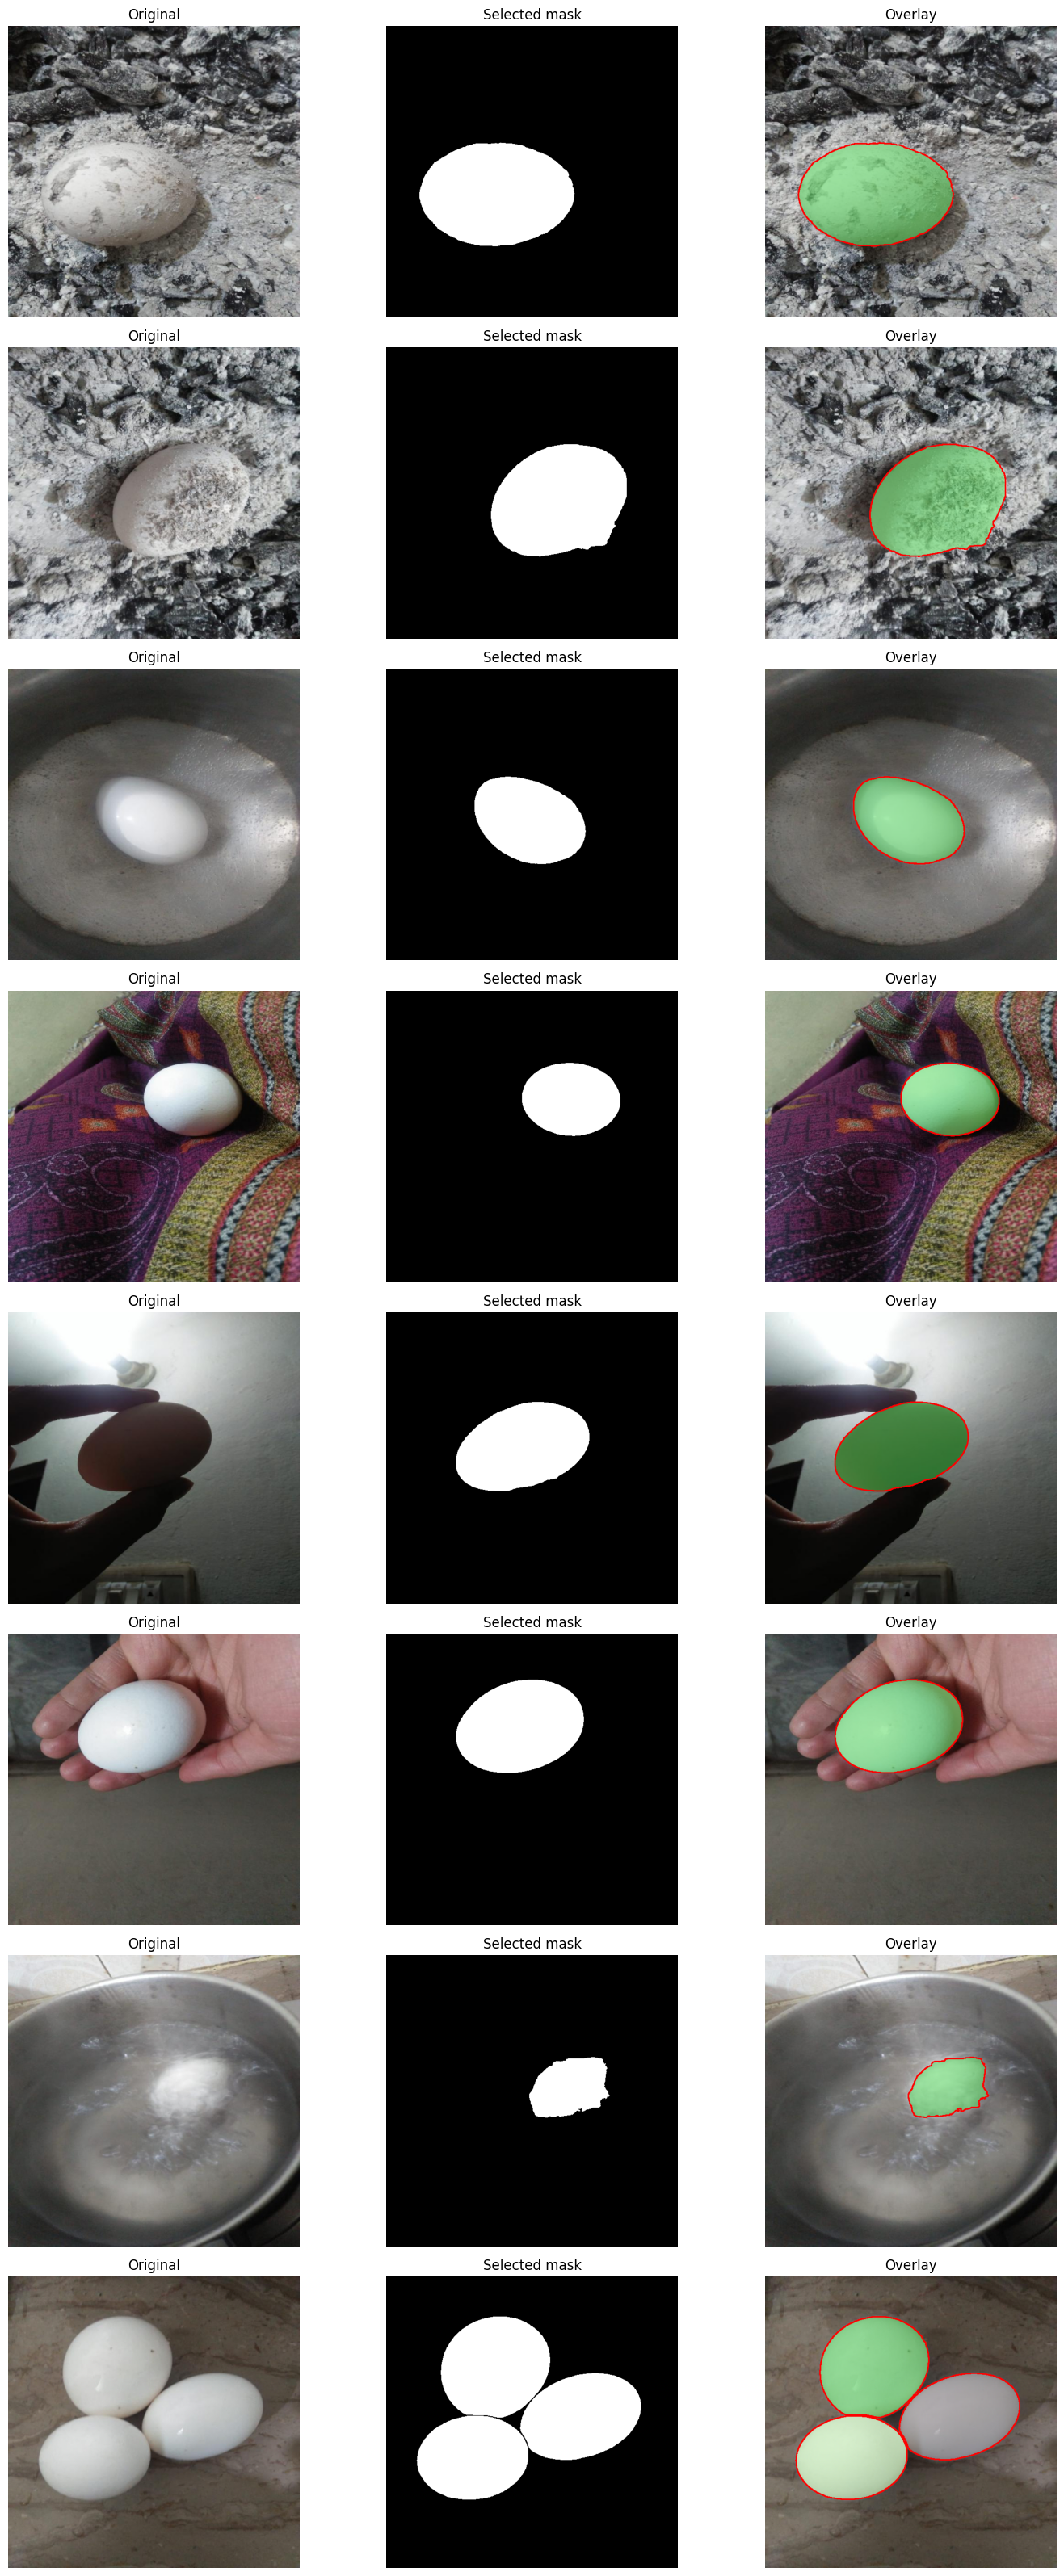

In [13]:
successful = results_df[results_df["status"] == "success"].copy()

if len(successful) == 0:
    print("No successful images to display.")
else:
    sample = successful.sample(min(8, len(successful)), random_state=SEED)
    fig, axes = plt.subplots(len(sample), 3, figsize=(15, 4 * len(sample)))
    if len(sample) == 1:
        axes = np.expand_dims(axes, axis=0)

    for row_idx, (_, row) in enumerate(sample.iterrows()):
        rel = Path(row["image"])
        original = np.asarray(Image.open(INPUT_DIR / rel).convert("RGB"))
        mask_path = COMBINED_MASK_DIR / rel.parent / f"{rel.stem}_mask.png"
        overlay_path = OVERLAY_DIR / rel.parent / f"{rel.stem}_overlay.png"

        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        overlay_bgr = cv2.imread(str(overlay_path))
        overlay = cv2.cvtColor(overlay_bgr, cv2.COLOR_BGR2RGB)

        axes[row_idx, 0].imshow(original)
        axes[row_idx, 0].set_title("Original")
        axes[row_idx, 1].imshow(mask, cmap="gray", vmin=0, vmax=255)
        axes[row_idx, 1].set_title("Selected mask")
        axes[row_idx, 2].imshow(overlay)
        axes[row_idx, 2].set_title("Overlay")

        for ax in axes[row_idx]:
            ax.axis("off")

    plt.tight_layout()
    plt.show()

,raw_sam_masks,selected_candidates,selected_mask_pixels
count,110.000000,110.000000,110.000000
mean,1.236364,1.227273,52851.945455
std,0.589313,0.600597,28858.696723
min,1.000000,0.000000,0.000000
25%,1.000000,1.000000,30762.000000
50%,1.000000,1.000000,49771.000000
75%,1.000000,1.000000,66000.750000
max,3.000000,3.000000,154835.000000


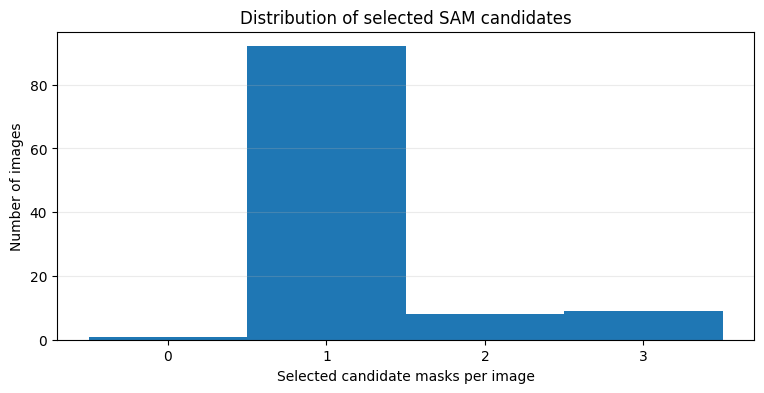

Images with zero selected candidates: 1


In [14]:
# Summarize the results and show how many candidates were found per image.
successful = results_df[results_df["status"] == "success"]

display(successful[[
    "raw_sam_masks", "selected_candidates", "selected_mask_pixels"
]].describe())

if len(successful):
    max_count = int(successful["selected_candidates"].max())
    bins = np.arange(-0.5, max_count + 1.5, 1)
    plt.figure(figsize=(9, 4))
    plt.hist(successful["selected_candidates"], bins=bins)
    plt.xlabel("Selected candidate masks per image")
    plt.ylabel("Number of images")
    plt.title("Distribution of selected SAM candidates")
    plt.xticks(range(max_count + 1))
    plt.grid(axis="y", alpha=0.25)
    plt.show()

print("Images with zero selected candidates:",
      int((successful["selected_candidates"] == 0).sum()))

## Check images with no detections or many detections

Zero-detection images: 1
Images with >=4 masks: 0


,image,raw_sam_masks,selected_candidates
26,train/egg/not_damaged_117_jpg.rf.d25ded9e7408f...,1,0


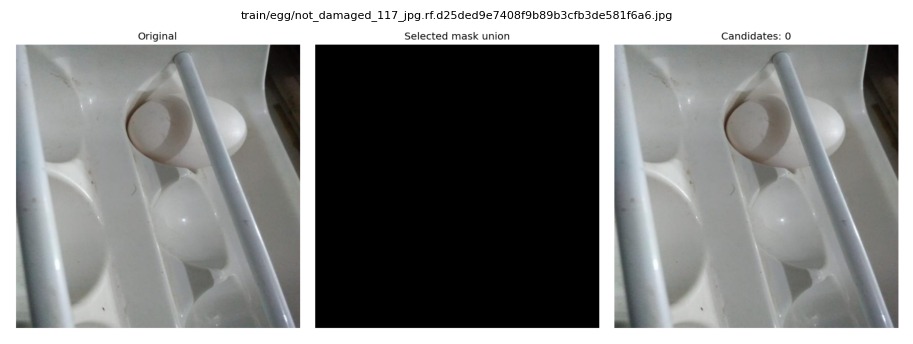

In [15]:
odd = successful[(successful["selected_candidates"] == 0) | (successful["selected_candidates"] >= 4)]
print("Zero-detection images:", int((successful["selected_candidates"] == 0).sum()))
print("Images with >=4 masks:", int((successful["selected_candidates"] >= 4).sum()))
display(odd[["image", "raw_sam_masks", "selected_candidates"]])

for _, row in odd.head(6).iterrows():
    rel = Path(row["image"])
    vis = VIS_DIR / rel.parent / f"{rel.stem}_visualization.png"
    if vis.exists():
        plt.figure(figsize=(12, 4))
        plt.imshow(Image.open(vis)); plt.axis("off"); plt.title(row["image"], fontsize=8)
        plt.show()

## Package the results for download

The notebook creates `/kaggle/working/task1_results.zip`. When it finishes, download the archive from Kaggle's **Output** panel.

In [16]:
ZIP_BASE = "/kaggle/working/task1_results"
ZIP_PATH = shutil.make_archive(
    ZIP_BASE,
    "zip",
    root_dir="/kaggle/working",
    base_dir="task1_results"
)

print("ZIP created:", ZIP_PATH)
print("Size (MB):", round(os.path.getsize(ZIP_PATH) / (1024**2), 2))

ZIP created: /kaggle/working/task1_results.zip
Size (MB): 86.37
